In [1]:
import cv2
from PIL import Image
import os
import os.path
import numpy as np
import torch
import torch.nn.functional as F
from torchinfo import summary
import pickle as pkl
import imageio.v2 as imageio
import torch

import matplotlib.pyplot as plt
# 
from core.models.resnet  import resnet101
from core.models import build_feature_extractor, build_classifier
from core.configs import cfg
import scipy.io as io

In [2]:
cfg.merge_from_file('configs/synthia/deeplabv2_r101_src.yaml')

In [3]:
cfg.freeze()

In [4]:
NUM_CLASSES = {"S": 16, "D": 1}
TASKNAMES = ["S", "D"]

In [5]:
from core.models.resnet  import resnet101
from core.models import build_feature_extractor, build_classifier
from core.configs import cfg

In [6]:
feature_extractor = build_feature_extractor(cfg, TASKNAMES)
classifier = build_classifier(cfg, TASKNAMES, NUM_CLASSES)

Loads checkpoint by http backend from path: https://download.pytorch.org/models/resnet101-5d3b4d8f.pth


In [7]:
a = torch.randn(2,3,640,360)
size = (640,360)

In [8]:
src_feats_back = feature_extractor['B'](a)
src_feats_depth = feature_extractor['D'](src_feats_back)
pred_depth = classifier['D'](src_feats_depth, size)

src_feats_trans = feature_extractor['T'](pred_depth)

In [ ]:
out

In [10]:
out['D'].shape

torch.Size([2, 2048, 80, 45])

In [9]:
a = torch.randn(2,2048,80,45)
b = torch.randn(2,2048,80,45)



In [13]:
c = torch.randn(2,2,2,2)
d = torch.randn(1,2,2,2,2)
f = torch.stack([v for v in d],dim=0)
e = torch.sum(f,dim=0)
e.shape

torch.Size([2, 2, 2, 2])

In [ ]:
c = torch.cat((a,b),dim = 1)
d = torch.add(a,b)
c.shape
d.shape

In [ ]:
classifier['D'](out['T'])

In [11]:
from torchview import draw_graph

In [12]:
model_graph4 = draw_graph(classifier['D'],src_feats_depth)
model_graph4.resize_graph(2)

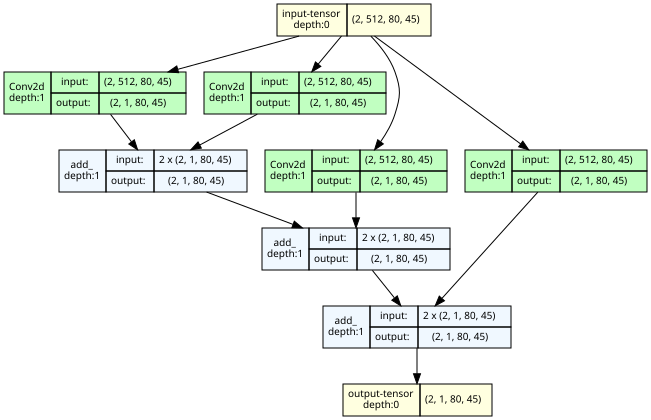

In [13]:
model_graph4.visual_graph


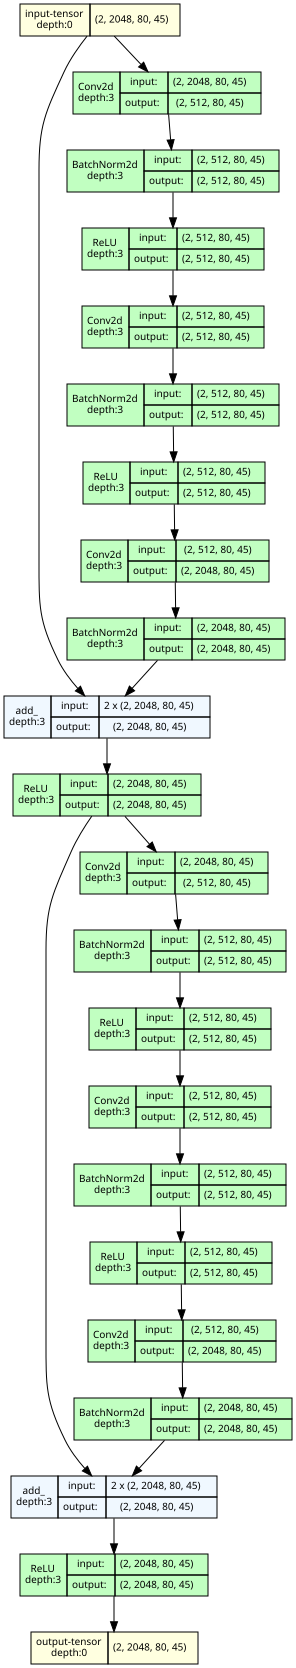

In [16]:
model_graph4 = draw_graph(feature_extractor['S'],src_feats_back)
model_graph4.resize_graph(2)
model_graph4.visual_graph

In [ ]:
model_graph2 = draw_graph(feature,a)
model_graph2.resize_graph(2)

In [ ]:
model_graph2.visual_graph

In [ ]:
model_graph1 = draw_graph(feature,a)
model_graph1.resize_graph(2)

In [ ]:
model_graph1.visual_graph

In [ ]:
model_graph = draw_graph(feature,a)
model_graph.resize_graph(2)

In [ ]:
model_graph.visual_graph

In [ ]:
model_graph = draw_graph(classifier['D'],out['D'])

In [ ]:
model_graph.visual_graph

In [ ]:
datapath = '/home/dauphin/Documents/Project/ProCA/datasets/synthia/RAND_CITYSCAPES/GT/LABELS'


In [ ]:
empty = {}
cnt = 0
for dirpath, dirnames, filenames in os.walk(datapath):
    for filename in [f for f in filenames if f.endswith(".png")]:
        # fname = os.path.join(dirpath,filename)
        # img = np.array(Image.open(fname), dtype=np.float32)
        # if len(np.unique(img, return_counts=True)[0]) <= 1:
        #     empty[fname] = np.unique(img, return_counts=True)
        cnt+=1

In [ ]:
np.unique(np.asarray(Image.open('datasets/synthia/RAND_CITYSCAPES/GT/LABELS/0000006.png'))[:, :, 1])

In [ ]:
imageio.imread('datasets/synthia/RAND_CITYSCAPES/GT/LABELS/0000006.png', format='PNG')

In [ ]:
empty

In [ ]:
path = '/home/dauphin/Documents/Project/ProCA/datasets/cityscapes/gtFine/train/jena/jena_000020_000019_gtFine_labelIds.png'
img = np.array(Image.open(path), dtype=np.float32)
np.unique(img, return_counts=True)[0]
img.shape

In [ ]:
src = open('datasets/cityscapes_train_list.txt', 'r').readlines()
target = open('datasets/synthia_train_list.txt', 'r').readlines()


In [ ]:
src2 = []
target2 = []

for temp in  target:
    target2.append(temp.strip())


for temp in  src:
    src2.append(temp.strip())     

In [ ]:
img1 = torch.rand((1,3,640,360))
img1.shape
img2  = F.interpolate(img1, size=[640,360], mode='bilinear', align_corners=True)
img2.shape

In [ ]:
torch.equal(img1,img2)

In [ ]:
label_to_file,file_to_label = pkl.load(open('datasets/synthia/synthia_label_info_working.p', 'rb'))
# f_not = pkl.load(open('datasets/synthia/synthia_label_info_not.p', 'rb'))
# f_check = pkl.load(open('datasets/synthia/synthia_label_info.p', 'rb'))

In [ ]:
path = 'datasets/synthia/RAND_CITYSCAPES/Depth/Depth/0007212.png'
label_pth = 'datasets/synthia/RAND_CITYSCAPES/synthia_mapped_to_cityscapes/0007212.png'

In [ ]:
depth = np.array(cv2.imread(path, flags=cv2.IMREAD_ANYDEPTH), dtype=np.float32)
depth.shape
depth = 655.36 / (depth + 0.01)


In [ ]:
depth = 'datasets/cityscapes/depth/train/aachen/aachen_000000_000019_depth_stereoscopic.mat'

In [ ]:
name = 'aachen/aachen_000000_000019_leftImg8bit.png'
name.split("_leftImg8bit")[0] + "_depth_stereoscopic.mat"

In [ ]:
depth_map = io.loadmat(depth)["depth_map"] 

In [ ]:
depth_map.dtype

In [ ]:
depth_map = np.clip(depth_map, 0., 655.35)


In [ ]:
depth_map[depth_map<0.1] = 655.35


In [ ]:
# depth_map = 655.36 / (depth_map + 0.01)
depth_map.dtype

In [ ]:
type(depth_map)

In [ ]:
depth_map = depth_map.astype(np.float32)

In [ ]:
depth

In [ ]:
type(depth_map)
depth_map.dtype

In [ ]:
depth_base =  os.path.join('datasets/cityscapes/', "depth", 'train')

In [ ]:
depth_base

In [31]:
from torch import nn
import torch
import numpy as np
import torch.nn.functional as F


def get_bins(type, K):
    d = []
    if type == 'SID':
        a = 1
        b = 655.36
        for i in range(K):
            t_i = np.exp(np.log(a) + (np.log(b / a) * i) / K)
            d.append(np.ceil(t_i))
    elif type == 'SID2': # the bin process as n the CTRL cvpr21 paper
        a = 1
        b = 655.36
        for i in range(K):
            p1 = 1 - (2 * i + 1) / (2 * K)
            p2 = (2 * i + 1) / (2 * K)
            t_i = (a ** p1) * (b ** p2)
            d.append(t_i)
    d.sort()
    print('Depth bins in meters:')
    for i in range(K):
        print('{:.2f}'.format(d[i]), end=" ")
    print()
    return d


class DepthProb(nn.Module):
    def __init__(self):
        super(DepthProb, self).__init__()
        self.num_depth_bins = 15
        self.sig = 1
        d = get_bins('SID2', self.num_depth_bins)
        depth_intval = torch.zeros(self.num_depth_bins, dtype=torch.float)
        for i in range(self.num_depth_bins):
            depth_intval[i] = d[i] * 100.0  # m --> cm
        print('Depth bins in cm:')
        for i in range(self.num_depth_bins):
            print('{:.2f}'.format(depth_intval[i]), end=" ")
        print()
        depth_intval = 65536.0 / (depth_intval + 1)  # converting the depth bins to inverse depth bins
        self.depint = depth_intval
        print('Inverse Depth bins in cm:')
        for i in range(self.num_depth_bins):
            print('{:.2f}'.format(self.depint[i]), end=" ")
        print()

    def forward(self, feat):
        c = []
        for i in range(self.num_depth_bins):
            c.append(-torch.square((feat - self.depint[i])) / self.sig)
            print("Hello")
        return F.softmax(torch.cat(c, 1), dim=1)


class Prob2Entropy(nn.Module):
    def __init__(self):
        super(Prob2Entropy, self).__init__()

    def forward(self, prob):
        n,c,h, w = prob.size()
       
        return -torch.mul(prob, torch.log2(prob + 1e-30)) / np.log2(c)



        

In [32]:
path = 'datasets/synthia/RAND_CITYSCAPES/Depth/Depth/0000531.png'
label_pth = 'datasets/synthia/RAND_CITYSCAPES/synthia_mapped_to_cityscapes/0007212.png'

In [33]:
depth = np.array(cv2.imread(path, flags=cv2.IMREAD_ANYDEPTH), dtype=np.float32)

In [34]:
depth = 655.36 / (depth + 0.01)
depth.shape

(760, 1280)

In [35]:
depth = torch.tensor(depth)


In [41]:
depth = torch.unsqueeze(depth,dim = 0)
depth.shape

torch.Size([1, 1, 760, 1280])

In [ ]:
plt.imshow(depth, cmap='gray')  # You can choose a different colormap if needed
plt.axis('off')  # Turn off axis labels
plt.show()

In [43]:
get_depth_prob = DepthProb()
prob_to_entropy = Prob2Entropy()


Depth bins in meters:
1.24 1.91 2.95 4.54 7.00 10.78 16.61 25.60 39.45 60.78 93.66 144.31 222.37 342.64 527.96 
Depth bins in cm:
124.13 191.27 294.72 454.13 699.75 1078.22 1661.40 2560.00 3944.62 6078.14 9365.61 14431.16 22236.51 34263.52 52795.54 
Inverse Depth bins in cm:
523.74 340.85 221.61 143.99 93.52 60.73 39.42 25.59 16.61 10.78 7.00 4.54 2.95 1.91 1.24 


In [44]:

depth_prob = get_depth_prob(torch.tensor(depth))
depth_prob.shape
np.unique(depth_prob,return_counts=True)

/tmp/ipykernel_10906/3962440529.py:1: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  depth_prob = get_depth_prob(torch.tensor(depth))


Hello
Hello
Hello
Hello
Hello
Hello
Hello
Hello
Hello
Hello
Hello
Hello
Hello
Hello
Hello


(array([0.000000e+00, 1.401298e-45, 2.802597e-45, ..., 8.891543e-01,
        8.891544e-01, 8.906422e-01], dtype=float32),
 array([9128533,   23189,   16973, ...,       3,       1,  102756]))

In [45]:
depth_entropy = prob_to_entropy(depth_prob)
depth_entropy.max()

tensor(0.1358)

TypeError: Invalid shape (1, 15, 560, 560) for image data

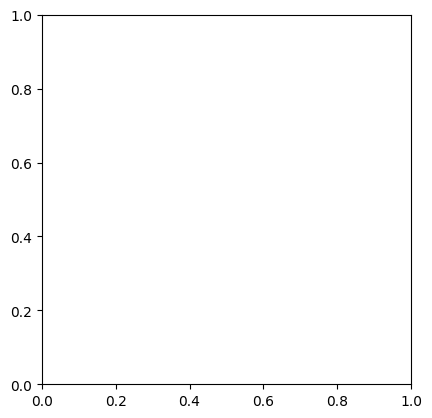

In [48]:
plt.imshow(depth_entropy[:,:,:560,:560]) 
plt.show()

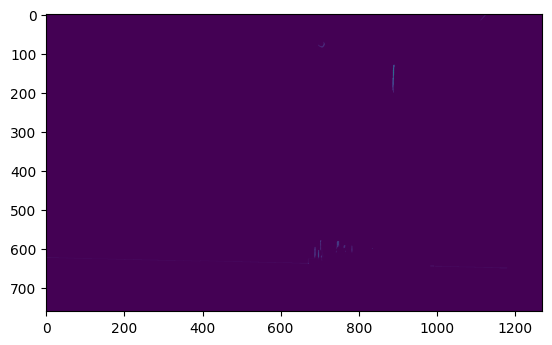

In [24]:
plt.imshow(depth_prob[:,:1270]) 
plt.show()